# Subgroup and Customer Targeting Analysis

This notebook examines whether the revenue impact of email marketing varies across customers with different purchase histories, and whether these differences support personalized campaign targeting.

Customers are divided into three mutually exclusive groups based on their pre-experiment purchasing behavior:

- **Mens Only:** Previously purchased men's merchandise only.
- **Womens Only:** Previously purchased women's merchandise only.
- **Both:** Previously purchased merchandise from both categories.

These groups represent merchandise purchase history, not customer gender.

The primary outcome is revenue per randomized customer, including customers with zero spending. Detailed subgroup calculations are available in `sql/05_subgroup_analysis.sql`.

Because these subgroup analyses were developed during data exploration, the findings are considered exploratory.

In [13]:
import pandas as pd

df = pd.read_csv("../data/raw/hillstrom.csv")

# Define mutually exclusive purchase-history groups
def classify_history(row):
    if row["mens"] == 1 and row["womens"] == 0:
        return "Mens Only"
    elif row["mens"] == 0 and row["womens"] == 1:
        return "Womens Only"
    elif row["mens"] == 1 and row["womens"] == 1:
        return "Both"
    else:
        return "Neither"

df["history_group"] = df.apply(classify_history, axis=1)

df["history_group"].value_counts()

history_group
Mens Only      28818
Womens Only    28734
Both            6448
Name: count, dtype: int64

## 1. Observed Subgroup Treatment Effects

The table below summarizes the estimated effects of each email campaign relative to Control within each purchase-history group.

| Customer Group | Men's Email Revenue Lift | Women's Email Revenue Lift | Men's Email Conversion Lift | Women's Email Conversion Lift |
|---|---:|---:|---:|---:|
| Both | +$1.8250 | +$0.1619 | +1.50 pp | +0.53 pp |
| Mens Only | +$0.6827 | +$0.2784 | +0.60 pp | +0.06 pp |
| Womens Only | +$0.6157 | +$0.6316 | +0.57 pp | +0.51 pp |

Men's Email shows the largest observed revenue lift in the Both group and outperforms Women's Email in the Mens Only group. Among Womens Only customers, the two campaigns produce nearly identical revenue lift estimates.

These differences suggest possible treatment effect heterogeneity, but descriptive estimates alone are insufficient to establish that campaign effectiveness varies systematically across customer groups.

## 2. Treatment Effect Heterogeneity

An OLS regression with treatment-by-subgroup interaction terms is used to assess whether campaign effects vary across purchase-history groups.

The model includes email treatment, purchase-history group, and their interaction. HC3 heteroskedasticity-robust standard errors are used to account for potentially unequal spending variances.

A joint Wald test evaluates the following hypotheses:

- **H0:** Email treatment effects are equal across purchase-history groups.
- **H1:** At least one email treatment effect differs across groups.

The test evaluates all four interaction coefficients jointly at a significance level of 0.05.

In [3]:
import statsmodels.formula.api as smf

# OLS regression with treatment-by-subgroup interactions
model = smf.ols(
    'spend ~ C(segment, Treatment(reference="No E-Mail")) * '
    'C(history_group, Treatment(reference="Womens Only"))',
    data=df
).fit(cov_type="HC3")

# Joint Wald tests for regression terms
wald_table = model.wald_test_terms(scalar=True).table

wald_table

,statistic,pvalue,df_constraint
Intercept,27.991359,1.218584e-07,1
"C(segment, Treatment(reference=""No E-Mail""))",20.028314,4.476173e-05,2
"C(history_group, Treatment(reference=""Womens Only""))",4.619436,9.928922e-02,2
"C(segment, Treatment(reference=""No E-Mail"")):C(history_group, Treatment(reference=""Womens Only""))",6.890085,1.418120e-01,4


### Interaction Test Results

The joint Wald test did not identify statistically significant treatment effect heterogeneity across purchase-history groups:

- **Wald test:** $\chi^2(4) = 6.8901$
- **P-value:** $p = 0.1418$

At the 5% significance level, we fail to reject the null hypothesis that treatment effects are equal across purchase-history groups.

Although the observed revenue lift differs across segments, the current evidence is insufficient to conclude that customers respond differently to email treatments based on their purchase histories.

This result does not establish that treatment effects are identical. It indicates that the experiment did not provide sufficiently strong evidence of heterogeneity.

## 3. Subgroup Revenue Effects and Confidence Intervals

To assess the precision of the subgroup treatment effect estimates, 95% confidence intervals are calculated using Welch's method.

These intervals quantify uncertainty in each campaign's revenue effect relative to Control within a customer group. They do not directly test whether treatment effects differ between customer groups.

The intervals are exploratory and are not adjusted for multiple comparisons.

In [5]:
from scipy.stats import ttest_ind

results = []

for group in ["Both", "Mens Only", "Womens Only"]:
    subgroup = df[df["history_group"] == group]

    control = subgroup.loc[
        subgroup["segment"] == "No E-Mail", "spend"
    ]

    for campaign in ["Mens E-Mail", "Womens E-Mail"]:
        treatment = subgroup.loc[
            subgroup["segment"] == campaign, "spend"
        ]

        test = ttest_ind(treatment, control, equal_var=False)
        ci = test.confidence_interval(confidence_level=0.95)

        results.append({
            "history_group": group,
            "campaign": campaign,
            "revenue_effect": treatment.mean() - control.mean(),
            "ci_lower": ci.low,
            "ci_upper": ci.high
        })

subgroup_effects = pd.DataFrame(results)

subgroup_effects.round(4)

,history_group,campaign,revenue_effect,ci_lower,ci_upper
0,Both,Mens E-Mail,1.8250,0.4897,3.1603
1,Both,Womens E-Mail,0.1619,-0.8136,1.1374
2,Mens Only,Mens E-Mail,0.6827,0.2471,1.1183
3,Mens Only,Womens E-Mail,0.2784,-0.1236,0.6803
4,Womens Only,Mens E-Mail,0.6157,0.2697,0.9618
5,Womens Only,Womens E-Mail,0.6316,0.2951,0.9682


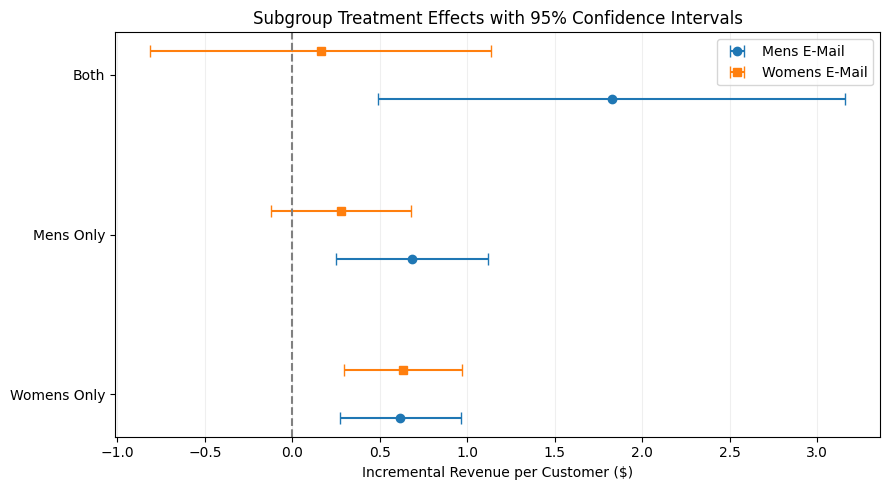

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

groups = ["Both", "Mens Only", "Womens Only"]

for i, campaign in enumerate(["Mens E-Mail", "Womens E-Mail"]):
    data = (
        subgroup_effects[subgroup_effects["campaign"] == campaign]
        .set_index("history_group")
        .loc[groups]
    )

    y = [j + (0.15 if i == 0 else -0.15) for j in range(3)]

    ax.errorbar(
        data["revenue_effect"],
        y,
        xerr=[
            data["revenue_effect"] - data["ci_lower"],
            data["ci_upper"] - data["revenue_effect"]
        ],
        fmt="o" if i == 0 else "s",
        capsize=4,
        label=campaign
    )

ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(range(3), groups)
ax.invert_yaxis()

ax.set_xlabel("Incremental Revenue per Customer ($)")
ax.set_title("Subgroup Treatment Effects with 95% Confidence Intervals")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### Interpretation

Men's Email produced positive revenue lift estimates with 95% confidence intervals excluding zero in all three purchase-history groups. Women's Email showed a positive effect with an interval excluding zero in the Womens Only group.

The largest estimated effect was observed for Men's Email in the Both group (+$1.8250 per customer). However, its relatively wide confidence interval ($0.4897 to $3.1603) indicates considerable uncertainty about the magnitude of the effect.

Although several individual subgroup effects have confidence intervals excluding zero, the joint interaction test was not statistically significant (p = 0.1418). Therefore, these results do not establish that purchase-history-based targeting would improve campaign performance.

All subgroup confidence intervals are exploratory and unadjusted for multiple comparisons.

## 4. Business Recommendations and Limitations

### Business Recommendations

**1. Prioritize Men's Email as the leading campaign candidate.**

Both email campaigns significantly increased revenue per customer relative to Control, including after Holm correction in the overall treatment analysis.

Men's Email delivered the larger estimated revenue lift (+$0.7698 per customer versus +$0.4244 for Women's Email). A direct comparison also favored Men's Email (+$0.3454, nominal p = 0.0305).

These results support prioritizing Men's Email when the objective is to maximize revenue per customer and campaign economics are comparable. However, the direct comparison was added during exploratory analysis and was not included in the earlier multiple-testing family. Further validation is advisable before adopting a definitive long-term rollout strategy.

**2. Avoid premature purchase-history-based targeting.**

Although Men's Email generated particularly strong observed revenue lift among customers who previously purchased both merchandise categories, the joint interaction test was not statistically significant (p = 0.1418).

The experiment therefore does not provide sufficient evidence to recommend different email campaigns for different purchase-history groups.

**3. Evaluate profitability and validate targeting in future experiments.**

Campaign decisions should account for contribution margins, email costs, and longer-term customer outcomes rather than revenue alone.

Future experiments should prespecify campaign comparisons and subgroup hypotheses, with adequate sample sizes to evaluate whether personalized targeting generates incremental value.

### Limitations

- **Exploratory analyses:** The direct campaign comparison and purchase-history subgroup analyses were not prespecified. Their findings should be interpreted cautiously.
- **Subgroup uncertainty:** The Both group has fewer observations, resulting in relatively imprecise revenue effect estimates.
- **Revenue versus profit:** Campaign costs and product-level contribution margins are unavailable, preventing a reliable assessment of incremental profitability.
- **Limited outcome information:** The dataset does not contain detailed purchase timing or long-term customer outcomes.

## 5. Conclusion

The randomized experiment provides evidence that both email campaigns increase customer revenue, with Men's Email emerging as the strongest overall candidate.

However, the analysis does not establish that purchase-history-based personalization improves outcomes. A reasonable next step is to prioritize Men's Email while validating its incremental profitability and testing whether more targeted campaign allocation provides additional benefits.